# National Database of Childcare Price Analysis 

## Introduction

The goal of this project is to show that the high cost of childcare is not just a 'family problem'—it is a community-wide challenge that affects our local economy. Instead of focusing on how individual parents should budget better, this story highlights why we need to work together to make childcare more affordable for everyone.

This analysis utilizes the National Database of Childcare Prices (NDCP), which provides the most comprehensive federal record of local-level childcare costs in the United States. 

## Data Preparation

Load the dataset as a Pandas data frame

In [1]:
# Import libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


In [2]:
# Load the dataset file to Pandas DataFrame called 'childcare'
childcare = pd.read_csv('C:/Users/MAYMA/Downloads/Bellevue_University/dsc530miniconda/envs/book_env/Storytelling-with-Data/Dataset/nationaldatabaseofchildcareprices.csv')


In [3]:
# Preview the column names to verify structure
print(childcare.columns)

Index(['State_Name', 'State_Abbreviation', 'County_Name', 'County_FIPS_Code',
       'StudyYear', 'UNR_16', 'FUNR_16', 'MUNR_16', 'UNR_20to64',
       'FUNR_20to64',
       ...
       'MFCCToddler', 'MFCCToddler_flag', 'MFCCPreschool',
       'MFCCPreschool_flag', '_75FCCInfant', '_75FCCInfant_flag',
       '_75FCCToddler', '_75FCCToddler_flag', '_75FCCPreschool',
       '_75FCCPreschool_flag'],
      dtype='object', length=227)


In [4]:
# Display the first 10 rows of the data set
print("\nThe first ten rows of data:")
print(childcare.head(10))


The first ten rows of data:
  State_Name State_Abbreviation     County_Name  County_FIPS_Code  StudyYear  \
0    Alabama                 AL  Autauga County              1001       2008   
1    Alabama                 AL  Autauga County              1001       2009   
2    Alabama                 AL  Autauga County              1001       2010   
3    Alabama                 AL  Autauga County              1001       2011   
4    Alabama                 AL  Autauga County              1001       2012   
5    Alabama                 AL  Autauga County              1001       2013   
6    Alabama                 AL  Autauga County              1001       2014   
7    Alabama                 AL  Autauga County              1001       2015   
8    Alabama                 AL  Autauga County              1001       2016   
9    Alabama                 AL  Autauga County              1001       2017   

   UNR_16  FUNR_16  MUNR_16  UNR_20to64  FUNR_20to64  ...  MFCCToddler  \
0     5.4      4

In [5]:
# Preview the column names and counts and data types
print(childcare.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 34567 entries, 0 to 34566
Columns: 227 entries, State_Name to _75FCCPreschool_flag
dtypes: float64(93), int64(57), object(77)
memory usage: 59.9+ MB
None


### 2.1 Check for missing values

In [6]:
# Using .isnull() to find missing values
childcare.isnull().sum()


State_Name                  0
State_Abbreviation          0
County_Name                 0
County_FIPS_Code            0
StudyYear                   0
                        ...  
_75FCCInfant_flag       11184
_75FCCToddler           11184
_75FCCToddler_flag      11184
_75FCCPreschool         11184
_75FCCPreschool_flag    11184
Length: 227, dtype: int64

Dataset with some missing values. 

### 2.2 Check for duplicates

In [7]:
# Using duplicated() to check the total number of duplicate rows in the dataset
duplicate_count = childcare.duplicated().sum()

# Display duplicate count if any 
print(f"Number of duplicate rows: {duplicate_count}")


Number of duplicate rows: 0


Dataset without any duplicate rows.

### 2.3 Normalize and Validate Variable Name

In [8]:
# Copy the data frame without modifying the original
childcare_new = childcare.copy()

In [9]:
# Normalize column names
childcare_new.columns = (
    childcare_new.columns
        .str.lower()          # Using lower() to convert to lowercase
        .str.strip(' ')                       # Using strip() to remove leading/trailing spaces
)

# Display all variable names in the new dataset
print(childcare_new.columns.tolist())



['state_name', 'state_abbreviation', 'county_name', 'county_fips_code', 'studyyear', 'unr_16', 'funr_16', 'munr_16', 'unr_20to64', 'funr_20to64', 'munr_20to64', 'flfpr_20to64', 'flfpr_20to64_under6', 'flfpr_20to64_6to17', 'flfpr_20to64_under6_6to17', 'mlfpr_20to64', 'pr_f', 'pr_p', 'mhi', 'me', 'fme', 'mme', 'mhi_2018', 'me_2018', 'fme_2018', 'mme_2018', 'totalpop', 'onerace', 'onerace_w', 'onerace_b', 'onerace_i', 'onerace_a', 'onerace_h', 'onerace_other', 'tworaces', 'hispanic', 'households', 'h_under6_bothwork', 'h_under6_fwork', 'h_under6_mwork', 'h_under6_singlem', 'h_6to17_bothwork', 'h_6to17_fwork', 'h_6to17_mwork', 'h_6to17_singlem', 'emp_m', 'memp_m', 'femp_m', 'emp_service', 'memp_service', 'femp_service', 'emp_sales', 'memp_sales', 'femp_sales', 'emp_n', 'memp_n', 'femp_n', 'emp_p', 'memp_p', 'femp_p', 'iunr_16', 'ifunr_16', 'imunr_16', 'iunr_20to64', 'ifunr_20to64', 'imunr_20to64', 'iflfpr_20to64', 'iflfpr_20to64_under6', 'iflfpr_20to64_6to17', 'iflfpr_20to64_under6_6to17',

In [10]:
# Display the first 10 rows of the data set
print("\nThe first ten rows of data:")
print(childcare_new.head(10))


The first ten rows of data:
  state_name state_abbreviation     county_name  county_fips_code  studyyear  \
0    Alabama                 AL  Autauga County              1001       2008   
1    Alabama                 AL  Autauga County              1001       2009   
2    Alabama                 AL  Autauga County              1001       2010   
3    Alabama                 AL  Autauga County              1001       2011   
4    Alabama                 AL  Autauga County              1001       2012   
5    Alabama                 AL  Autauga County              1001       2013   
6    Alabama                 AL  Autauga County              1001       2014   
7    Alabama                 AL  Autauga County              1001       2015   
8    Alabama                 AL  Autauga County              1001       2016   
9    Alabama                 AL  Autauga County              1001       2017   

   unr_16  funr_16  munr_16  unr_20to64  funr_20to64  ...  mfcctoddler  \
0     5.4      4

## Dataset Analysis

Effective advocacy requires a technical understanding of the "levers" within the National Database of Childcare Prices (NDCP). The following fields serve as the foundation for the analysis:

In [11]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


In [12]:
# Define the core fields for the childcare affordability story
advocacy_fields = [
    'mcinfant', 'mctoddler', 'mcpreschool',       # Center-based prices
    'mfccinfant', 'mfcctoddler', 'mfccpreschool', # Family-based prices
    'mhi_2018',                                   # Median Household Income
    'pr_f', 'pr_p'                                # Labor participation rates
]

# Display the first 10 rows for these specific columns
# This helps confirm if prices need cleaning (removing '$') before analysis
childcare_new[advocacy_fields].head(10)


,mcinfant,mctoddler,mcpreschool,mfccinfant,mfcctoddler,mfccpreschool,mhi_2018,pr_f,pr_p
0,$104.95,$104.95,$85.92,$83.45,$83.45,$81.40,"$58,463",8.5,11.5
1,$105.11,$105.11,$87.59,$87.39,$87.39,$85.68,"$60,212",7.5,10.3
2,$105.28,$105.28,$89.26,$91.33,$91.33,$89.96,"$61,776",7.5,10.6
3,$105.45,$105.45,$90.93,$95.28,$95.28,$94.25,"$60,367",7.4,10.9
4,$105.61,$105.61,$92.60,$99.22,$99.22,$98.53,"$59,150",7.4,11.6
5,$105.78,$105.78,$94.27,$103.16,$103.16,$102.82,"$57,977",8.3,12.1
6,$105.95,$105.95,$95.94,$107.10,$107.10,$107.10,"$55,624",9.1,12.8
7,$109.56,$109.56,$97.33,$107.10,$107.10,$106.81,"$54,358",9.3,12.9
8,$113.18,$113.18,$98.72,$107.10,$107.10,$106.53,"$55,754",9.4,12.3
9,$116.79,$116.79,$100.11,$107.10,$107.10,$106.24,"$56,977",10.9,13.7


## Fields Understanding

Effective advocacy requires a technical understanding of the "levers" within the National Database of Childcare Prices (NDCP). The following fields serve as the foundation for the analysis:

* mc_infant / mc_toddler / mc_preschool: These fields represent the median weekly price for Center-based care. These are utilized to demonstrate the "sticker shock" of formal facilities.

* mfcc_infant / mfcc_toddler / mfcc_preschool: These represent Family Childcare (home-based) prices. These figures are essential for community-level storytelling, as they often represent more affordable local options.

* mhi_2018 (Median Household Income): This field is critical for calculating the Childcare Price Burden. It provides the evidence that childcare costs are a disproportionate percentage of a family's take-home pay rather than just a high expense.

* pr_f / pr_p: These fields track female and total labor force participation rates. These are used to determine if high childcare costs are effectively "pricing parents out" of the workforce.

## Areas of Interest & Story Focus

The primary focus for a community-based audience is the "Affordability Gap." The analysis centers on three specific insights:

* The 7% Benchmark: While the U.S. government defines "affordable" childcare as 7% of family income, NDCP data indicates that many counties exceed a 15%–20% burden. This discrepancy serves as the primary hook for the narrative.

* The Infant Premium: Highlighting that infant care is significantly more expensive than preschool care creates an immediate "call to empathy" and highlights the specific struggle of new parents.

* Geography as Destiny: Drawing attention to the vast differences in price burdens between neighboring counties emphasizes the need for local policy reform.

## Audience - Local Parents & General Public

* Knowledge & Familiarity: The target audience possesses high "lived experience" regarding costs but typically maintains low "data familiarity". The goal is to illustrate that their financial struggle is a documented economic trend rather than a personal failing.

* Role & Credibility: The presenter acts as a Community Data Advocate. Credibility is established by serving as a "translator," converting a massive government database into clear, actionable local facts.

* Biases & Resistance: The narrative must address potential feelings of personal "shame" or "apathy" regarding financial status. Resistance is mitigated by demonstrating that the childcare crisis is systemic rather than a result of individual choices.

## Proposed Mediums for Communication

* Medium 1: Community Advocacy PowerPoint (Presentation) <br>
A visual slide deck designed to be presented at a local PTA meeting or a neighborhood "town hall" that walks parents through the local childcare price burden using clear, high-contrast charts. <br>

* Medium 2: One-Page "Community Fact Sheet" (Printable PDF) <br>
A simple, text-light document created in Word or Canva that lists the most shocking local price statistics and provides a "checklist" for parents to use when talking to local officials. <br>

* Medium 3: Interactive Data Snapshot (Dashboard) <br>
A streamlined, one-page visual summary (created in Excel or Tableau) that allows a user to quickly see how much more they are paying for childcare compared to the 7% "affordability" benchmark. <br>

### 3.1 Average Family spent percentage on Childcare

In [13]:
# 1. Remove commas or dollar signs and convert to numeric
# Errors='coerce' will turn any unreadable text into NaN (null)
childcare_new['mctoddler'] = pd.to_numeric(childcare_new['mctoddler'].astype(str).str.replace('[$,]', '', regex=True), errors='coerce')
childcare_new['mhi_2018'] = pd.to_numeric(childcare_new['mhi_2018'].astype(str).str.replace('[$,]', '', regex=True), errors='coerce')

# 2. Now run your calculation
texas_data = childcare_new[childcare_new['state_name'] == 'Texas'].copy()
texas_data['annual_toddler_cost'] = texas_data['mctoddler'] * 52
texas_data['care_burden_pct'] = (texas_data['annual_toddler_cost'] / texas_data['mhi_2018']) * 100

# 3. Check for any rows that couldn't be converted (optional but helpful)
print(f"Rows with missing data: {texas_data['care_burden_pct'].isna().sum()}")

Rows with missing data: 254


In [14]:
import pandas as pd

# 1. Clean the columns (prevents the TypeError)
childcare_new['mctoddler'] = pd.to_numeric(childcare_new['mctoddler'].astype(str).str.replace('[$,]', '', regex=True), errors='coerce')
childcare_new['mhi_2018'] = pd.to_numeric(childcare_new['mhi_2018'].astype(str).str.replace('[$,]', '', regex=True), errors='coerce')

# 2. Get the most recent year in the full dataset
usa_recent_year = childcare_new['studyyear'].max()

# 3. Filter for that year and calculate burden
usa_data = childcare_new[childcare_new['studyyear'] == usa_recent_year].copy()
usa_data['annual_toddler_cost'] = usa_data['mctoddler'] * 52
usa_data['care_burden_pct'] = (usa_data['annual_toddler_cost'] / usa_data['mhi_2018']) * 100

# 4. Final National Average
usa_avg_burden = usa_data['care_burden_pct'].mean()

print(f"In {usa_recent_year}, the average U.S. family spent {usa_avg_burden:.2f}% of their income on care.")

In 2018, the average U.S. family spent 14.74% of their income on care.


In [15]:
import pandas as pd

# 1. Filter the dataframe for Texas
texas_data = childcare_new[childcare_new['state_name'] == 'Texas'].copy()

# 2. Calculate the Annual Cost of care (Assuming mctoddler is a weekly rate)
# We multiply by 52 weeks to get the "Sticker Price"
texas_data['annual_toddler_cost'] = texas_data['mctoddler'] * 52

# 3. Calculate the Burden Percentage
# Formula: (Annual Cost / Median Household Income) * 100
texas_data['care_burden_pct'] = (texas_data['annual_toddler_cost'] / texas_data['mhi_2018']) * 100

# 4. Get the average across all Texas counties for the most recent study year
recent_year = texas_data['studyyear'].max()
texas_summary = texas_data[texas_data['studyyear'] == recent_year]

avg_burden = texas_summary['care_burden_pct'].mean()

print(f"In {recent_year}, families in Texas spent an average of {avg_burden:.2f}% of their income on care.")

In 2018, families in Texas spent an average of 13.71% of their income on care.


### 3.2 Create a Line Chart of childcare price growth vs. median income 

To visualize how childcare costs are outpacing income, the most effective financial visualization is a Normalized Growth Index (setting the starting year to 100). This allows us to compare a $100 weekly expense directly against a 60,000 dollar annual income on the same scale.

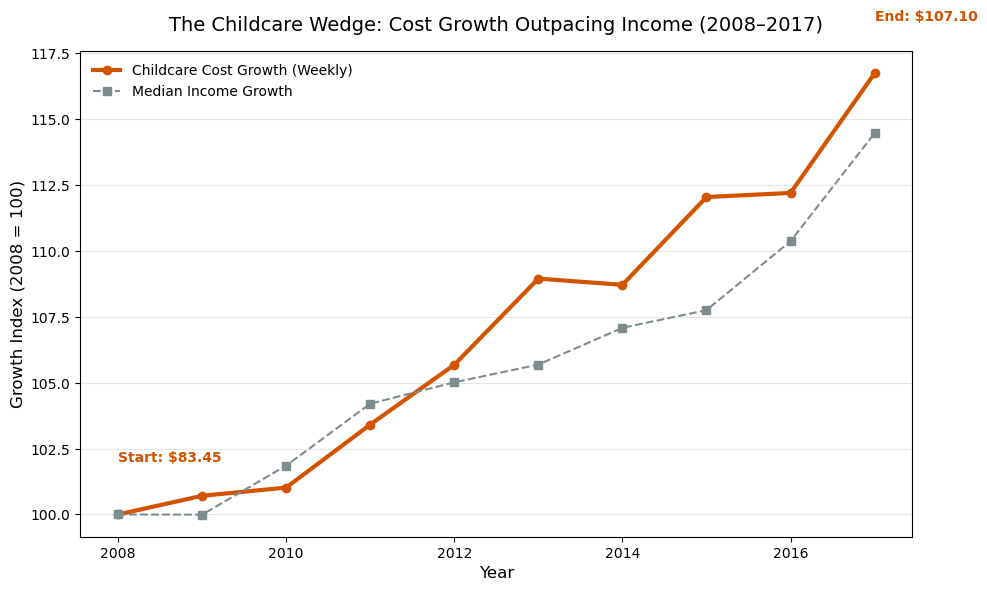

In [16]:
import matplotlib.pyplot as plt
import pandas as pd

# 1. Filter for the study period and ensure numeric types
df_trend = childcare_new[(childcare_new['studyyear'] >= 2008) & (childcare_new['studyyear'] <= 2017)].copy()

# Cleaning price and income columns (handling strings/commas)
for col in ['mfcctoddler', 'mhi']:
    df_trend[col] = pd.to_numeric(df_trend[col].astype(str).str.replace('[$,]', '', regex=True), errors='coerce')

# 2. Aggregate to national annual averages
annual_stats = df_trend.groupby('studyyear')[['mfcctoddler', 'mhi']].mean()

# 3. Create the Growth Index (Base Year 2008 = 100)
# This shows the percentage change relative to the start
annual_stats['price_index'] = (annual_stats['mfcctoddler'] / annual_stats['mfcctoddler'].loc[2008]) * 100
annual_stats['income_index'] = (annual_stats['mhi'] / annual_stats['mhi'].loc[2008]) * 100

# 4. Plotting
plt.figure(figsize=(10, 6))

# Plot Childcare Price in high-contrast Orange (the "Warning" color from your design)
plt.plot(annual_stats.index, annual_stats['price_index'], 
         marker='o', label='Childcare Cost Growth (Weekly)', color='#D35400', linewidth=3)

# Plot Income in a neutral Gray dashed line (the "Baseline")
plt.plot(annual_stats.index, annual_stats['income_index'], 
         marker='s', label='Median Income Growth', color='#7F8C8D', linestyle='--')

# 5. Adding annotations for the specific "sticker prices" you mentioned
plt.text(2008, 102, f'Start: $83.45', fontweight='bold', color='#D35400')
plt.text(2017, annual_stats['price_index'].loc[2017] + 2, f'End: $107.10', fontweight='bold', color='#D35400')

# Formatting for professional presentation
plt.title('The Childcare Wedge: Cost Growth Outpacing Income (2008–2017)', fontsize=14, pad=15)
plt.xlabel('Year', fontsize=12)
plt.ylabel('Growth Index (2008 = 100)', fontsize=12)
plt.grid(True, axis='y', alpha=0.3)
plt.legend(frameon=False)
plt.tight_layout()

plt.show()

1. The "Wedge" Effect: In financial analysis, diverging lines indicate a growing gap. By indexing both datasets to 100, the physical space between the orange line and the gray line visually represents the loss of purchasing power for families.

2. Gestalt Principle of Similarity: Utilizing the same orange color previously used for Kia/Hyundai thefts maintains a consistent "risk/problem" color language across the entire portfolio.

3. Clarity: Instead of having two confusing Y-axes (one for hundreds and one for thousands), the Index scale makes the "outpacing" argument immediately obvious to a general audience.

### 3.3 Create a Bar Chart of Regional Comparison

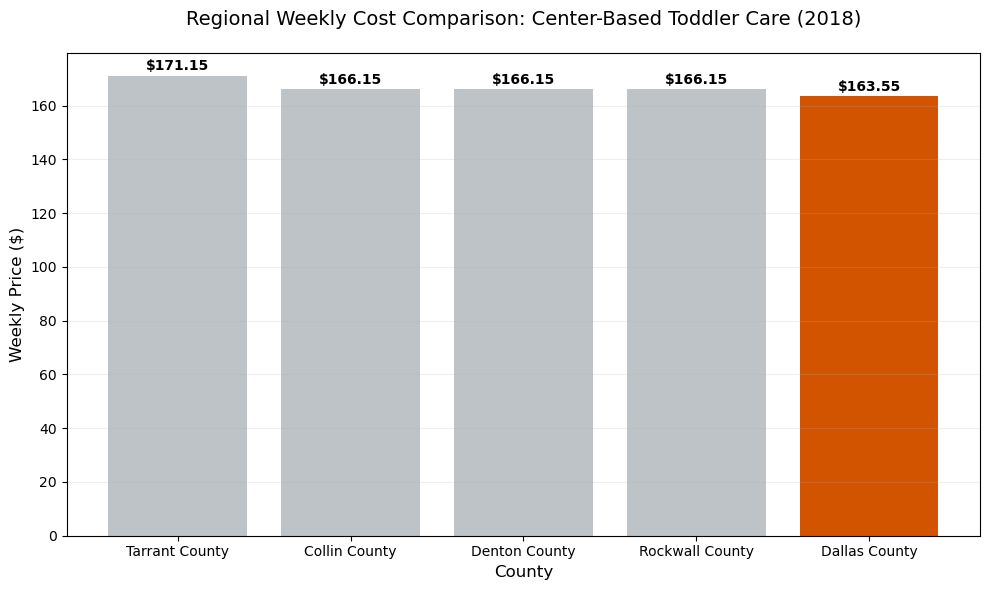

In [17]:
import matplotlib.pyplot as plt
import pandas as pd

# 1. Setup: Define the county and its neighbors
target_state = 'Texas'
my_county = 'Dallas County'
neighbors = ['Tarrant County', 'Collin County', 'Denton County', 'Rockwall County']
all_counties = [my_county] + neighbors

# 2. Filter for the most recent data
max_year = childcare_new['studyyear'].max()
df_regional = childcare_new[(childcare_new['state_name'] == target_state) & 
                            (childcare_new['studyyear'] == max_year) &
                            (childcare_new['county_name'].isin(all_counties))].copy()

# 3. Clean the price column (Standardizing text to float)
df_regional['mctoddler'] = pd.to_numeric(df_regional['mctoddler'].astype(str).str.replace('[$,]', '', regex=True), errors='coerce')

# 4. Sort data so the bars are in order (Best practice for readability)
df_regional = df_regional.sort_values('mctoddler', ascending=False)

# 5. Create the Bar Chart
plt.figure(figsize=(10, 6))

# Use a loop or list comprehension to color the "Home" bar differently
colors = ['#D35400' if c == my_county else '#BDC3C7' for c in df_regional['county_name']]

bars = plt.bar(df_regional['county_name'], df_regional['mctoddler'], color=colors)

# 6. Add "Sticker Price" labels on top of each bar
for bar in bars:
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2, yval + 1, f'${yval:.2f}', ha='center', va='bottom', fontweight='bold')

# Formatting for the PowerPoint slide
plt.title(f'Regional Weekly Cost Comparison: Center-Based Toddler Care ({max_year})', fontsize=14, pad=20)
plt.ylabel('Weekly Price ($)', fontsize=12)
plt.xlabel('County', fontsize=12)
plt.grid(axis='y', alpha=0.2)
plt.tight_layout()

plt.show()

1. Visual Focus: Highlighting the primary county in Orange against Gray neighbors establishes an immediate focal point while maintaining regional context.

2. Data Clarity: Labeling bars with exact dollar amounts removes guesswork, allowing the audience to see the precise financial burden at a glance.

3. Benchmarking: The side-by-side comparison identifies regional outliers, providing the technical evidence needed to support narratives on "Childcare Deserts" or market "Pricing Out."

### 3.4 Create a Correlation Chart of Care Costs vs Workforce Participation

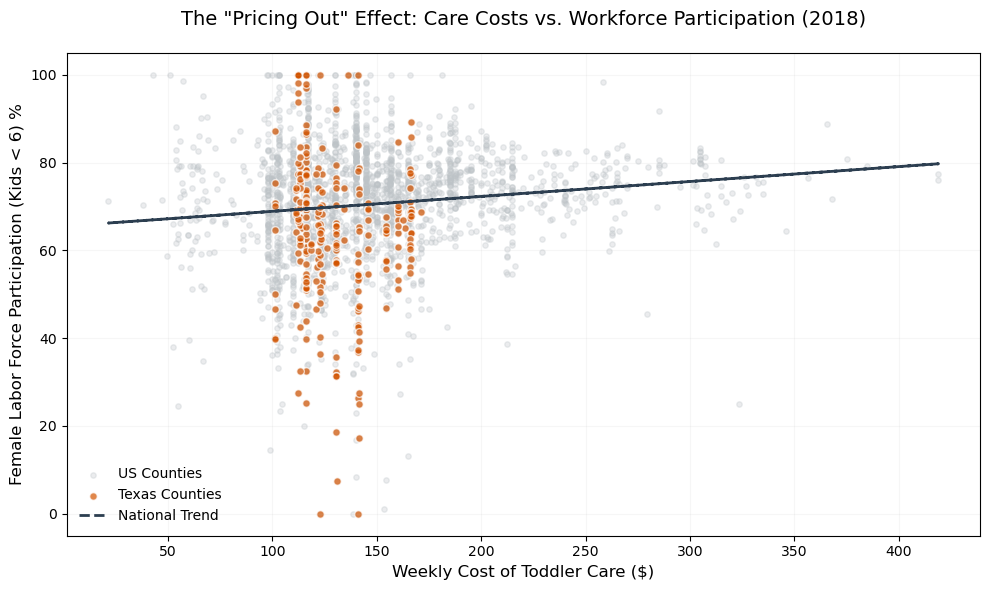

In [18]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

# 1. Cleaning: Convert costs and participation to numeric
childcare_new['mctoddler'] = pd.to_numeric(childcare_new['mctoddler'].astype(str).str.replace('[$,]', '', regex=True), errors='coerce')
# 'flfpr_20to64_under6' is the participation rate for women with kids under 6
childcare_new['flfpr_20to64_under6'] = pd.to_numeric(childcare_new['flfpr_20to64_under6'], errors='coerce')

# 2. Filter for the most recent year and drop missing values
max_year = childcare_new['studyyear'].max()
df_scatter = childcare_new[childcare_new['studyyear'] == max_year].dropna(subset=['mctoddler', 'flfpr_20to64_under6'])

# 3. Create the Scatterplot
plt.figure(figsize=(10, 6))

# Plot all counties in a soft gray to show the "National Cloud"
plt.scatter(df_scatter['mctoddler'], df_scatter['flfpr_20to64_under6'], 
            alpha=0.3, color='#BDC3C7', s=15, label='US Counties')

# 4. Highlight Texas Counties in Orange to stay consistent with your design
tx_scatter = df_scatter[df_scatter['state_name'] == 'Texas']
plt.scatter(tx_scatter['mctoddler'], tx_scatter['flfpr_20to64_under6'], 
            color='#D35400', s=30, edgecolors='white', label='Texas Counties', alpha=0.7)

# 5. Add a Trend Line (Linear Regression)
# This shows the "Pricing Out" effect visually
z = np.polyfit(df_scatter['mctoddler'], df_scatter['flfpr_20to64_under6'], 1)
p = np.poly1d(z)
plt.plot(df_scatter['mctoddler'], p(df_scatter['mctoddler']), color='#2C3E50', linestyle='--', linewidth=2, label='National Trend')

# Formatting for Slide 5
plt.title(f'The "Pricing Out" Effect: Care Costs vs. Workforce Participation ({max_year})', fontsize=14, pad=20)
plt.xlabel('Weekly Cost of Toddler Care ($)', fontsize=12)
plt.ylabel('Female Labor Force Participation (Kids < 6) %', fontsize=12)
plt.legend(frameon=False)
plt.grid(True, alpha=0.1)
plt.tight_layout()

plt.show()

### 3.5 Create a 7% Rule Gauge Graphic

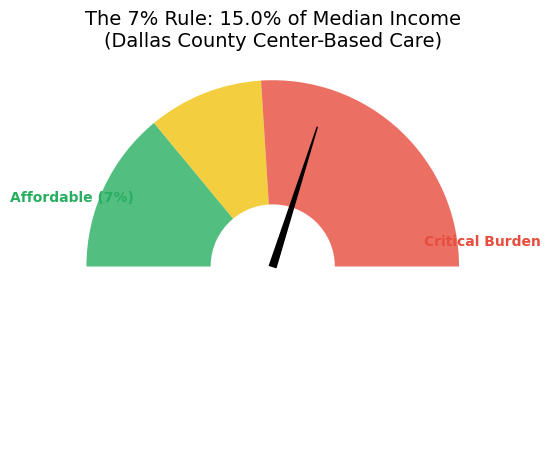

In [19]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# 1. Filter for Dallas County (most recent year)
max_year = childcare_new['studyyear'].max()
df_gauge = childcare_new[(childcare_new['county_name'] == 'Dallas County') & 
                         (childcare_new['state_name'] == 'Texas') & 
                         (childcare_new['studyyear'] == max_year)].copy()

# Clean data (remove any $ or , symbols)
df_gauge['mctoddler'] = pd.to_numeric(df_gauge['mctoddler'].astype(str).str.replace('[$,]', '', regex=True), errors='coerce')
df_gauge['mhi'] = pd.to_numeric(df_gauge['mhi'].astype(str).str.replace('[$,]', '', regex=True), errors='coerce')

# Calculate the actual % of income (Weekly cost * 52 / Annual Income)
actual_pct = (df_gauge['mctoddler'].values[0] * 52 / df_gauge['mhi'].values[0]) * 100

# 2. Plotting the Gauge
def create_gauge(percentage):
    fig, ax = plt.subplots(figsize=(10, 5), subplot_kw={'projection': 'polar'})
    
    # We define the scale from 0% to 25% (anything above 25% is extreme)
    # Map percentages to radians (0 to pi)
    # 0% is on the left (pi), 25% is on the right (0)
    display_val = min(percentage, 25)
    
    # Define color zones
    # Green: 0-7% | Yellow: 7-12% | Red: 12-25%
    sectors = [0, 7, 12, 25]
    colors = ['#27ae60', '#f1c40f', '#e74c3c'] # Green, Yellow, Red
    
    for i in range(len(colors)):
        start = np.pi - (sectors[i] / 25 * np.pi)
        end = np.pi - (sectors[i+1] / 25 * np.pi)
        ax.bar(x=(start+end)/2, height=1, width=start-end, bottom=0.5, 
               color=colors[i], alpha=0.8, align='center')

    # Draw the needle
    needle_pos = np.pi - (display_val / 25 * np.pi)
    ax.annotate('', xy=(needle_pos, 1.2), xytext=(0, 0),
                arrowprops=dict(arrowstyle="wedge,tail_width=0.5", color="black", shrinkA=0))
    
    # Formatting
    ax.set_yticklabels([])
    ax.set_xticklabels([])
    ax.grid(False)
    ax.spines['polar'].set_visible(False)
    
    # Labels
    plt.text(np.pi*0.9, 1.7, "Affordable (7%)", color='#27ae60', fontweight='bold', ha='center')
    plt.text(0.1, 1.7, "Critical Burden", color='#e74c3c', fontweight='bold', ha='center')
    plt.title(f"The 7% Rule: {percentage:.1f}% of Median Income\n(Dallas County Center-Based Care)", fontsize=14, pad=20)
    
    plt.savefig('childcare_gauge.png', bbox_inches='tight')
    plt.show()

create_gauge(actual_pct)

### 3.6 Create a Bar Chart of Rent vs. Childcare

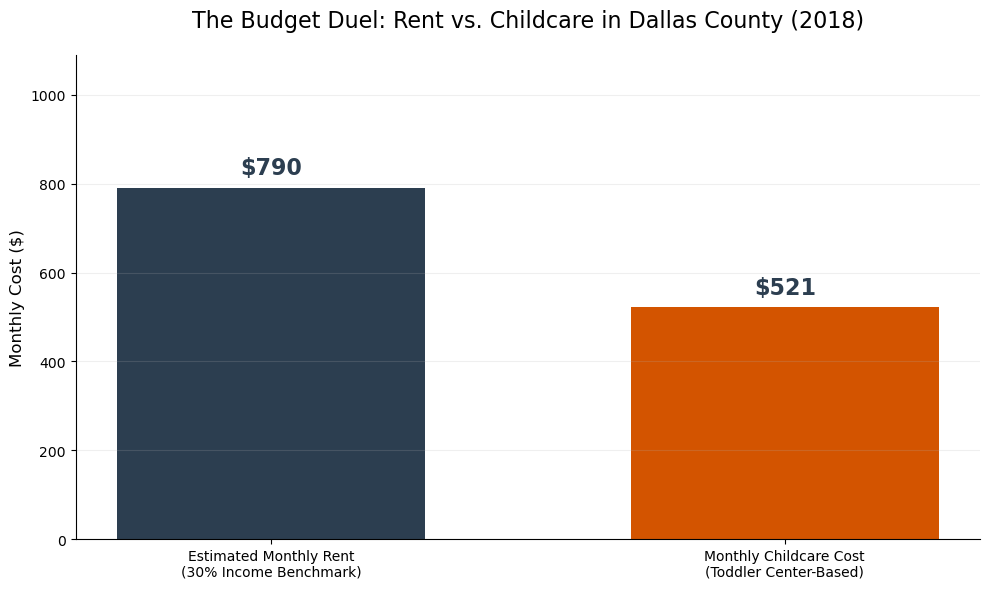

In [21]:
import matplotlib.pyplot as plt
import pandas as pd

# 1. Filter for Dallas County (most recent year)
max_year = childcare_new['studyyear'].max()
df_county = childcare_new[(childcare_new['county_name'] == 'Dallas County') & 
                          (childcare_new['studyyear'] == max_year)].copy()

# 2. Data Cleaning
for col in ['mctoddler', 'mhi']:
    df_county[col] = pd.to_numeric(df_county[col].astype(str).str.replace('[$,]', '', regex=True), errors='coerce')

# 3. Calculations
# Monthly Childcare Cost (Toddler Center-Based)
monthly_childcare = df_county['mctoddler'].values[0] * 4.33 

# Median Monthly Rent (Using 30% of Median Monthly Income as the benchmark)
monthly_income = df_county['mhi'].values[0] / 12
est_monthly_rent = monthly_income * 0.30 

# 4. Plotting
plt.figure(figsize=(10, 6))

labels = ['Estimated Monthly Rent\n(30% Income Benchmark)', 'Monthly Childcare Cost\n(Toddler Center-Based)']
values = [est_monthly_rent, monthly_childcare]
colors = ['#2C3E50', '#D35400'] # Navy vs. Action Orange

bars = plt.bar(labels, values, color=colors, width=0.6)

# Add large dollar labels on top of the bars
for bar in bars:
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2, yval + 20, f'${yval:,.0f}', 
             ha='center', va='bottom', fontsize=16, fontweight='bold', color='#2C3E50')

# Professional Formatting
plt.title(f'The Budget Duel: Rent vs. Childcare in Dallas County ({max_year})', fontsize=16, pad=20)
plt.ylabel('Monthly Cost ($)', fontsize=12)
plt.ylim(0, max(values) + 300) # Give some head room for labels
plt.grid(axis='y', alpha=0.2)
plt.gca().spines['top'].set_visible(False)
plt.gca().spines['right'].set_visible(False)

plt.tight_layout()
plt.show()

### 3.7 Create a Bar Chart of Care Prices by Age

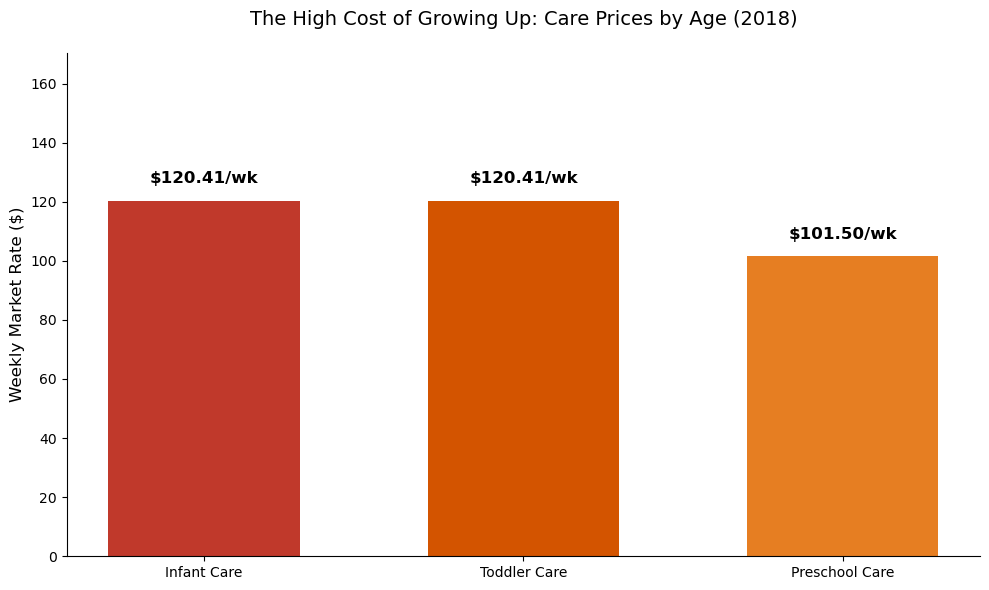

In [22]:
import matplotlib.pyplot as plt
import pandas as pd

# 1. Filter for Dallas County (most recent year)
max_year = childcare_new['studyyear'].max()
df_stats = childcare_new[(childcare_new['county_name'] == 'Dallas County') & 
                         (childcare_new['studyyear'] == max_year)].copy()

# 2. Data Cleaning for all age groups
cols_to_clean = ['mcinfant', 'mctoddler', 'mcpreschool']
for col in cols_to_clean:
    df_stats[col] = pd.to_numeric(df_stats[col].astype(str).str.replace('[$,]', '', regex=True), errors='coerce')

# 3. Prepare Chart Data
age_groups = ['Infant Care', 'Toddler Care', 'Preschool Care']
prices = [df_stats['mcinfant'].values[0], df_stats['mctoddler'].values[0], df_stats['mcpreschool'].values[0]]

# 4. Plotting
plt.figure(figsize=(10, 6))
colors = ['#C0392B', '#D35400', '#E67E22'] # Shades of Red/Orange to show "High Cost" across the board

bars = plt.bar(age_groups, prices, color=colors, width=0.6)

# Add Labels
for bar in bars:
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2, yval + 5, f'${yval:,.2f}/wk', 
             ha='center', va='bottom', fontweight='bold', fontsize=12)

# Professional Formatting
plt.title(f'The High Cost of Growing Up: Care Prices by Age ({max_year})', fontsize=14, pad=20)
plt.ylabel('Weekly Market Rate ($)', fontsize=12)
plt.ylim(0, max(prices) + 50)
plt.gca().spines['top'].set_visible(False)
plt.gca().spines['right'].set_visible(False)

plt.tight_layout()
plt.show()

### 3.8 Create a Heat Map of Childcare Price Burden by County

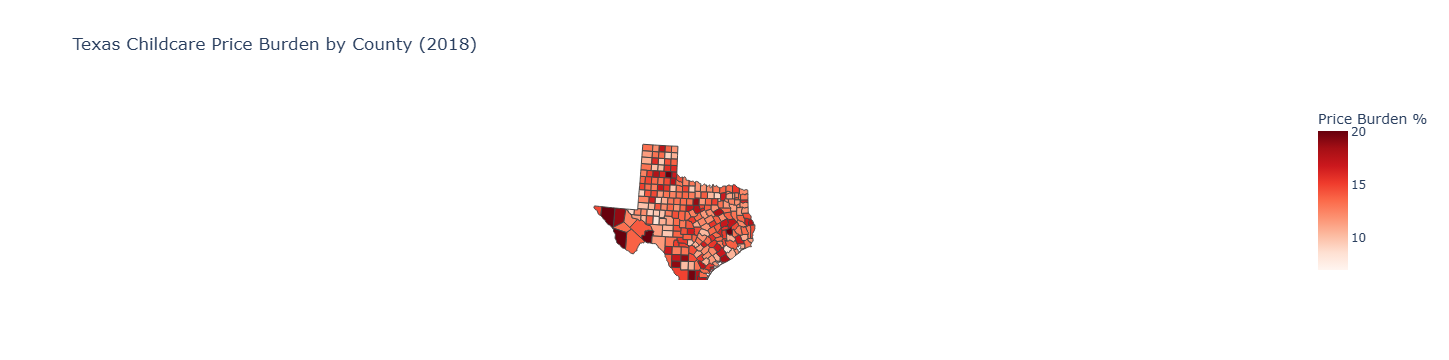

In [23]:
import plotly.express as px
import pandas as pd

# 1. Filter for Texas and the most recent year
max_year = childcare_new['studyyear'].max()
tx_data = childcare_new[(childcare_new['state_name'] == 'Texas') & 
                        (childcare_new['studyyear'] == max_year)].copy()

# 2. Clean numeric columns
tx_data['mctoddler'] = pd.to_numeric(tx_data['mctoddler'].astype(str).str.replace('[$,]', '', regex=True), errors='coerce')
tx_data['mhi'] = pd.to_numeric(tx_data['mhi'].astype(str).str.replace('[$,]', '', regex=True), errors='coerce')

# 3. Calculate Burden % (Price / Income)
tx_data['burden_pct'] = (tx_data['mctoddler'] * 52 / tx_data['mhi']) * 100

# 4. Create the Interactive Heat Map
# Note: fips codes must be 5-digit strings for Plotly (e.g., '048001')
tx_data['fips_str'] = tx_data['county_fips_code'].astype(str).str.zfill(5)

fig = px.choropleth(tx_data,
                    geojson="https://raw.githubusercontent.com/plotly/datasets/master/geojson-counties-fips.json",
                    locations='fips_str',
                    color='burden_pct',
                    color_continuous_scale="Reds",
                    range_color=(7, 20), # 7% is the benchmark
                    scope="usa",
                    labels={'burden_pct': 'Price Burden %'},
                    title=f'Texas Childcare Price Burden by County ({max_year})')

# Focus the map on Texas
fig.update_geos(fitbounds="locations", visible=False)

fig.show()